# NLP with Hugging Face transformers

**Goal:** Classify short sentences about football results *without training a model*, and explore text embeddings.

**Data:** 20 labelled sentences (victory, defeat, draw, comeback).

**Methods**
- **Zero-shot classification** with `facebook/bart-large-mnli`
- **Sentiment analysis** with DistilBERT (SST-2)
- **Text embeddings** (DistilBERT) + **K-means clustering** with the elbow method

**Results:** zero-shot classification labelled **17 of 20 sentences correctly (85%)** with no training data. All three errors were *victories* predicted as *comebacks*, two closely related labels.

**Takeaway:** pretrained transformers make useful text classifiers possible with zero labelled examples. The same approach can sort maintenance reports, customer feedback or sustainability disclosures.

---
*Coursework: M.Eng. Engineering & Sustainable Technology Management, AI / Machine Learning courses (2025–2026). Originally run in Google Colab.*

In [ ]:
! pip install transformers
from transformers import pipeline

In [ ]:
import pandas as pd

data = {
    "sentence": [
        "The team completed an incredible comeback after being two goals behind.",
        "Germany was eliminated after suffering a painful defeat.",
        "Spain won the match after scoring three goals in the second half.",
        "The match ended in a draw after both teams scored one goal.",
        "Brazil dominated the game and achieved a comfortable victory.",
        "Portugal suffered a surprising defeat against a lower-ranked opponent.",
        "France scored three late goals to complete a dramatic comeback.",
        "Argentina secured an impressive victory in the World Cup final.",
        "Neither team managed to score, so the game finished level.",
        "England was defeated after conceding a goal in extra time.",
        "The national team celebrated after defeating its strongest rival.",
        "Spain came from behind to secure an unforgettable victory.",
        "The players were disappointed after losing the quarterfinal.",
        "France advanced to the next round after winning by two goals.",
        "The goalkeeper made a late save to preserve the draw.",
        "Argentina recovered from a poor first half and won the match.",
        "The team lost despite creating several clear scoring opportunities.",
        "The teams produced an exciting match that ended with equal scores.",
        "The players refused to give up and overturned the result in the final minutes.",
        "Italy secured a narrow victory with a goal in the final minute."
    ],

    "true_label": [
        "comeback",
        "defeat",
        "victory",
        "draw",
        "victory",
        "defeat",
        "comeback",
        "victory",
        "draw",
        "defeat",
        "victory",
        "comeback",
        "defeat",
        "victory",
        "draw",
        "victory",
        "defeat",
        "draw",
        "comeback",
        "victory"
    ]
}

#df = pd.DataFrame(data)

#df

In [ ]:
import pandas as pd

df = pd.read_excel("/content/football_sentences_plain.xlsx")

df

,sentence;true_label,Unnamed: 1
0,The team completed an incredible comeback afte...,NaN
1,Germany was eliminated after suffering a painf...,NaN
2,Spain won the match after scoring three goals ...,NaN
3,The match ended in a draw after both teams sco...,NaN
4,Brazil dominated the game and achieved a comfo...,NaN
5,Portugal suffered a surprising defeat against ...,NaN
6,France scored three late goals to complete a d...,NaN
7,Argentina secured an impressive victory in the...,NaN
8,Neither team managed to score,so the game finished level.;draw
9,England was defeated after conceding a goal in...,NaN


In [ ]:
# Initialize the zero-shot classification pipeline. This is always like this.
classifier = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli"
)
# Labels that the model can assign. This is what you select.
categories = ["victory", "defeat", "draw", "comeback"]

config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [ ]:
text = "The team scored in the final minute and won the match."

result = classifier(text, categories)
result

{'sequence': 'The team scored in the final minute and won the match.',
 'labels': ['victory', 'comeback', 'draw', 'defeat'],
 'scores': [0.6801166534423828,
  0.30974000692367554,
  0.0067242346704006195,
  0.0034191710874438286]}

In [ ]:
# Convert the 'Sentence' column to a list of strings
texts = df['sentence'].astype(str).fillna("").tolist()
#convert to a list of strings with .astype(str).fillna("").tolist(), so the pipeline returns a list of dicts (one per row).
texts

['The team completed an incredible comeback after being two goals behind.',
 'Germany was eliminated after suffering a painful defeat.',
 'Spain won the match after scoring three goals in the second half.',
 'The match ended in a draw after both teams scored one goal.',
 'Brazil dominated the game and achieved a comfortable victory.',
 'Portugal suffered a surprising defeat against a lower-ranked opponent.',
 'France scored three late goals to complete a dramatic comeback.',
 'Argentina secured an impressive victory in the World Cup final.',
 'Neither team managed to score, so the game finished level.',
 'England was defeated after conceding a goal in extra time.',
 'The national team celebrated after defeating its strongest rival.',
 'Spain came from behind to secure an unforgettable victory.',
 'The players were disappointed after losing the quarterfinal.',
 'France advanced to the next round after winning by two goals.',
 'The goalkeeper made a late save to preserve the draw.',
 'Ar

In [ ]:
# Perform classification on the list of texts
results = classifier(texts, candidate_labels=categories, multi_label=True)
#
# Extract the predicted label and score
df['predicted_label'] = [result['labels'][0] if result['labels'] else None for result in results] # result is the each member of the list resutls
df['prediction_score'] = [result['scores'][0] if result['scores'] else None for result in results]

In [ ]:
df


,sentence,true_label,predicted_label,prediction_score
0,The team completed an incredible comeback afte...,comeback,comeback,0.989873
1,Germany was eliminated after suffering a painf...,defeat,defeat,0.996769
2,Spain won the match after scoring three goals ...,victory,comeback,0.992143
3,The match ended in a draw after both teams sco...,draw,draw,0.998720
4,Brazil dominated the game and achieved a comfo...,victory,victory,0.994133
5,Portugal suffered a surprising defeat against ...,defeat,defeat,0.997625
6,France scored three late goals to complete a d...,comeback,comeback,0.995402
7,Argentina secured an impressive victory in the...,victory,victory,0.985845
8,"Neither team managed to score, so the game fin...",draw,draw,0.999627
9,England was defeated after conceding a goal in...,defeat,defeat,0.998842


In [ ]:
from transformers import pipeline

sentiment_classifier = pipeline("sentiment-analysis")  #CREATE THE MODEL

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [ ]:
results = sentiment_classifier(
    df["sentence"].tolist(),
    truncation=True
)

df["sentiment"] = [result["label"] for result in results]
df["sentiment_score"] = [result["score"] for result in results]

df

,sentence,true_label,predicted_label,prediction_score,sentiment,sentiment_score
0,The team completed an incredible comeback afte...,comeback,comeback,0.989873,POSITIVE,0.999804
1,Germany was eliminated after suffering a painf...,defeat,defeat,0.996769,NEGATIVE,0.893441
2,Spain won the match after scoring three goals ...,victory,comeback,0.992143,POSITIVE,0.999437
3,The match ended in a draw after both teams sco...,draw,draw,0.998720,POSITIVE,0.958270
4,Brazil dominated the game and achieved a comfo...,victory,victory,0.994133,POSITIVE,0.999831
5,Portugal suffered a surprising defeat against ...,defeat,defeat,0.997625,NEGATIVE,0.992379
6,France scored three late goals to complete a d...,comeback,comeback,0.995402,POSITIVE,0.999617
7,Argentina secured an impressive victory in the...,victory,victory,0.985845,POSITIVE,0.999765
8,"Neither team managed to score, so the game fin...",draw,draw,0.999627,NEGATIVE,0.996748
9,England was defeated after conceding a goal in...,defeat,defeat,0.998842,NEGATIVE,0.725657


In [ ]:
from sklearn.cluster import KMeans
from transformers import pipeline
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

In [ ]:
# Load a Hugging Face pipeline for extracting embeddings
embedder = pipeline("feature-extraction", model="distilbert-base-uncased")

# Generate embeddings for each text
embeddings = np.array([embedder(text)[0][0] for text in texts])

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
# Apply k-means clustering
num_clusters = 4
kmeans = KMeans(n_clusters=num_clusters, random_state=42) # creat model
clusters = kmeans.fit_predict(embeddings) # fit the model

# Print the resulting clusters # prediction
for i, cluster in enumerate(clusters):
    print(f"Text: {texts[i]} - Cluster: {cluster}")

Text: The team completed an incredible comeback after being two goals behind. - Cluster: 1
Text: Germany was eliminated after suffering a painful defeat. - Cluster: 3
Text: Spain won the match after scoring three goals in the second half. - Cluster: 2
Text: The match ended in a draw after both teams scored one goal. - Cluster: 2
Text: Brazil dominated the game and achieved a comfortable victory. - Cluster: 0
Text: Portugal suffered a surprising defeat against a lower-ranked opponent. - Cluster: 0
Text: France scored three late goals to complete a dramatic comeback. - Cluster: 2
Text: Argentina secured an impressive victory in the World Cup final. - Cluster: 0
Text: Neither team managed to score, so the game finished level. - Cluster: 1
Text: England was defeated after conceding a goal in extra time. - Cluster: 2
Text: The national team celebrated after defeating its strongest rival. - Cluster: 1
Text: Spain came from behind to secure an unforgettable victory. - Cluster: 3
Text: The pla

In [ ]:
inertia_list = []
for k in np.arange(1,7): # the structure of loop should be consistent and the next lines should be after for .
    kmn =KMeans(n_clusters = k)
    kmn.fit(embeddings)# only add your data here the rest codes are the same for your dataset
    inertia_list.append(kmn.inertia_)# make a list which we add the caluculation of inertial in each loop to this list
inertia_list # this line is out of the loop and we undestood the loop ended here.

[278.59389167289163,
 200.48526427322238,
 168.8483505142555,
 148.61317128202728,
 143.1907179103754,
 113.76529485066158]

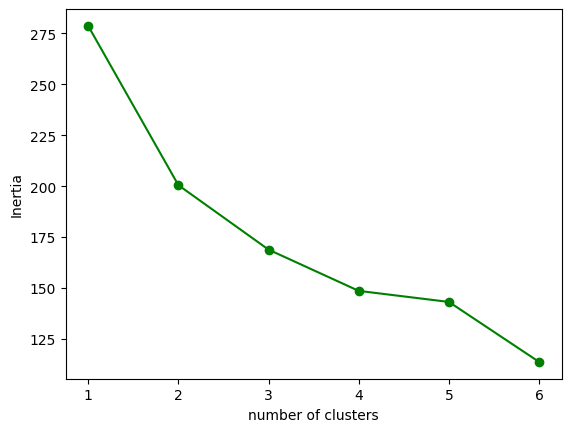

In [ ]:
import matplotlib.pyplot as plt
plt.plot(np.arange(1,7),inertia_list,'o-',c='green')
plt.xlabel('number of clusters')
plt.ylabel('Inertia')
plt.show()

In [ ]:
df["cluster"] = clusters

df

,sentence,true_label,predicted_label,prediction_score,sentiment,sentiment_score,cluster
0,The team completed an incredible comeback afte...,comeback,comeback,0.989873,POSITIVE,0.999804,1
1,Germany was eliminated after suffering a painf...,defeat,defeat,0.996769,NEGATIVE,0.893441,3
2,Spain won the match after scoring three goals ...,victory,comeback,0.992143,POSITIVE,0.999437,2
3,The match ended in a draw after both teams sco...,draw,draw,0.998720,POSITIVE,0.958270,2
4,Brazil dominated the game and achieved a comfo...,victory,victory,0.994133,POSITIVE,0.999831,0
5,Portugal suffered a surprising defeat against ...,defeat,defeat,0.997625,NEGATIVE,0.992379,0
6,France scored three late goals to complete a d...,comeback,comeback,0.995402,POSITIVE,0.999617,2
7,Argentina secured an impressive victory in the...,victory,victory,0.985845,POSITIVE,0.999765,0
8,"Neither team managed to score, so the game fin...",draw,draw,0.999627,NEGATIVE,0.996748,1
9,England was defeated after conceding a goal in...,defeat,defeat,0.998842,NEGATIVE,0.725657,2
